# Visualização do Pipeline — Classificação HSI-SWIR


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spectral
import cv2
from scipy.signal import savgol_filter

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

BASE_DIR     = r'C:\Users\jefferson.faria\Documents\GitHub\ic-2025'
HSI_ROOT     = os.path.join(BASE_DIR, 'dataSet', 'hsi_original')
FEATURES_DIR = os.path.join(BASE_DIR, 'features_selected')
RESULTS_DIR  = os.path.join(BASE_DIR, 'ml', 'results')
FIGS_DIR     = os.path.join(BASE_DIR, 'figures')
os.makedirs(FIGS_DIR, exist_ok=True)

BRANCHES = ['msc_mi', 'msc_xgb', 'log_mi', 'log_xgb', 'deriv_mi', 'deriv_xgb']
BRANCH_LABELS = {
    'msc_mi':   'MSC + MI',
    'msc_xgb':  'MSC + XGBoost',
    'log_mi':   'Log(1/R) + MI',
    'log_xgb':  'Log(1/R) + XGBoost',
    'deriv_mi': 'Savitzky-Golay + MI',
    'deriv_xgb':'Savitzky-Golay + XGBoost',
}
BRANCH_COLORS = {
    'msc_mi':   '#1565C0', 'msc_xgb':  '#42A5F5',
    'log_mi':   '#2E7D32', 'log_xgb':  '#66BB6A',
    'deriv_mi': '#E65100', 'deriv_xgb':'#FFA726',
}

# Lista todas as pastas de imagens disponíveis
pastas = sorted([p for p in os.listdir(HSI_ROOT) if os.path.isdir(os.path.join(HSI_ROOT, p))])
print(f'✅ {len(pastas)} imagens encontradas: {pastas}')

✅ 18 imagens encontradas: ['351_1_240506-160920', '420_240506-160205', '426_1_240506-160058', '491_240506-160846', '503B_240506-160006', '508_240506-160326', '534_240506-160510', '537_240506-160651', '539_240506-160131', '548A_240506-160359', '549_240506-160758', '553_240506-160724', '554A_240506-160433', '559_240506-160951', '560B_240506-160251', 'ATCC13_240506-161053', 'ATCC16_240506-161158', 'ATCC27_240506-161129']


## 1. Visualização do ROI — HoughCircles

c:\Users\jefferson.faria\AppData\Local\Programs\Python\Python311\Lib\site-packages\spectral\io\envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


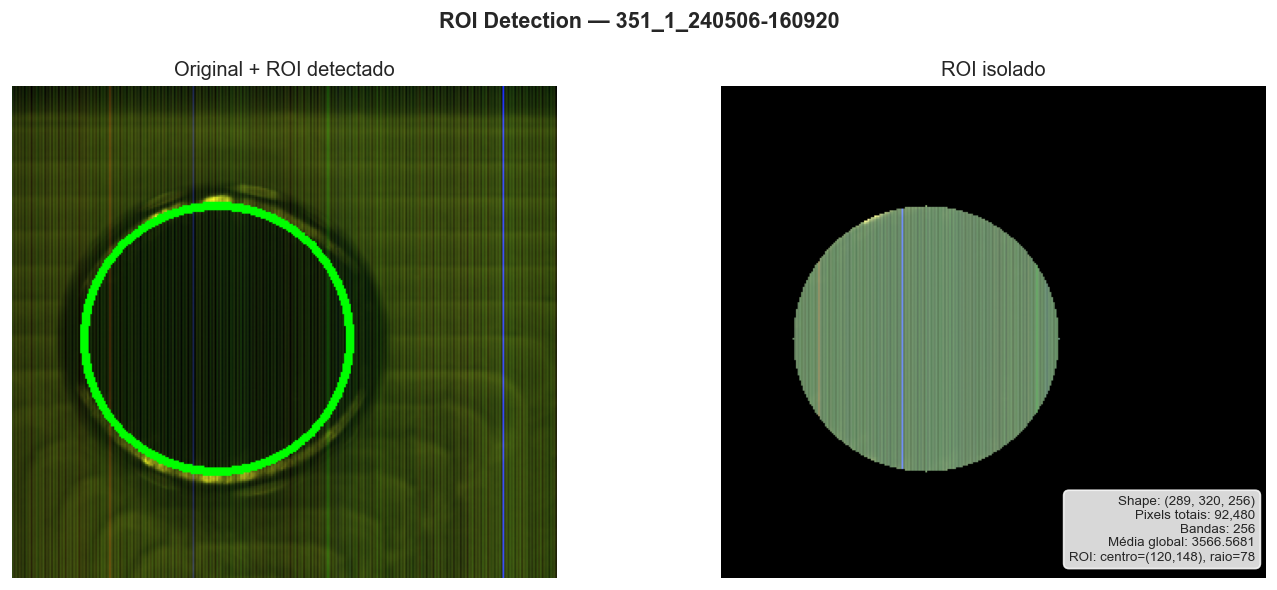

C:\Users\jefferson.faria\AppData\Local\Temp\ipykernel_32724\1825207207.py:72: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from current font.
  plt.tight_layout()
C:\Users\jefferson.faria\AppData\Local\Temp\ipykernel_32724\1825207207.py:72: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  plt.tight_layout()
C:\Users\jefferson.faria\AppData\Local\Temp\ipykernel_32724\1825207207.py:74: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from current font.
  plt.savefig(os.path.join(FIGS_DIR, f'roi_{folder_name}.png'), bbox_inches='tight')
C:\Users\jefferson.faria\AppData\Local\Temp\ipykernel_32724\1825207207.py:74: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  plt.savefig(os.path.join(FIGS_DIR, f'roi_{folder_name}.png'), bbox_inches='tight')
c:\Users\jefferson.faria\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from curre

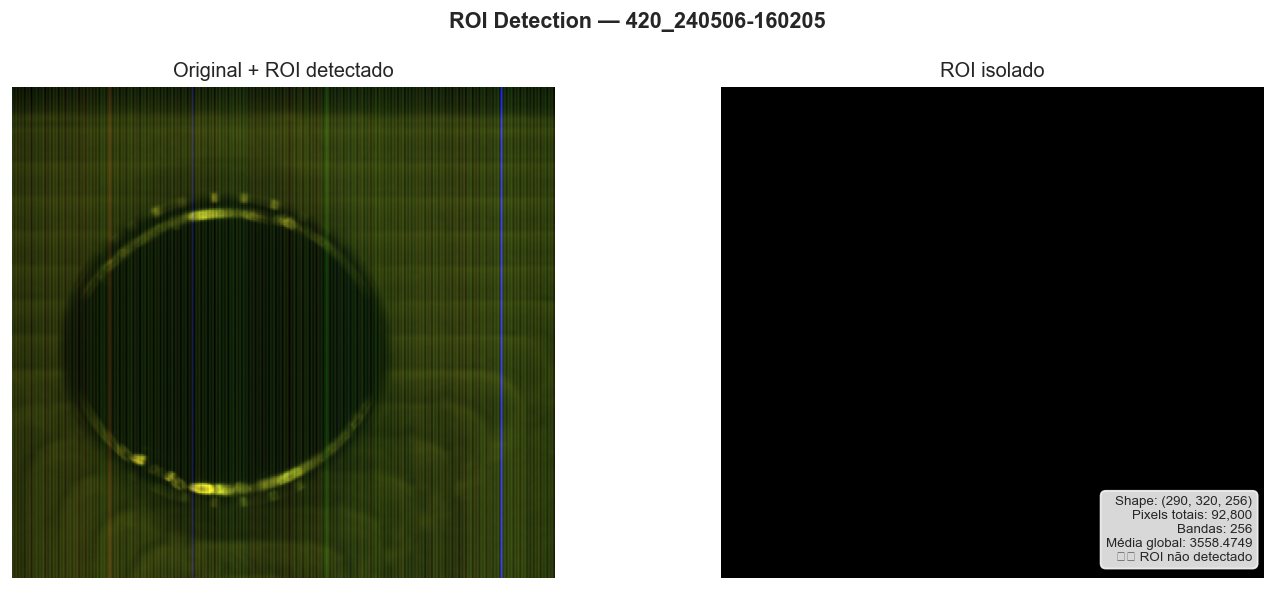

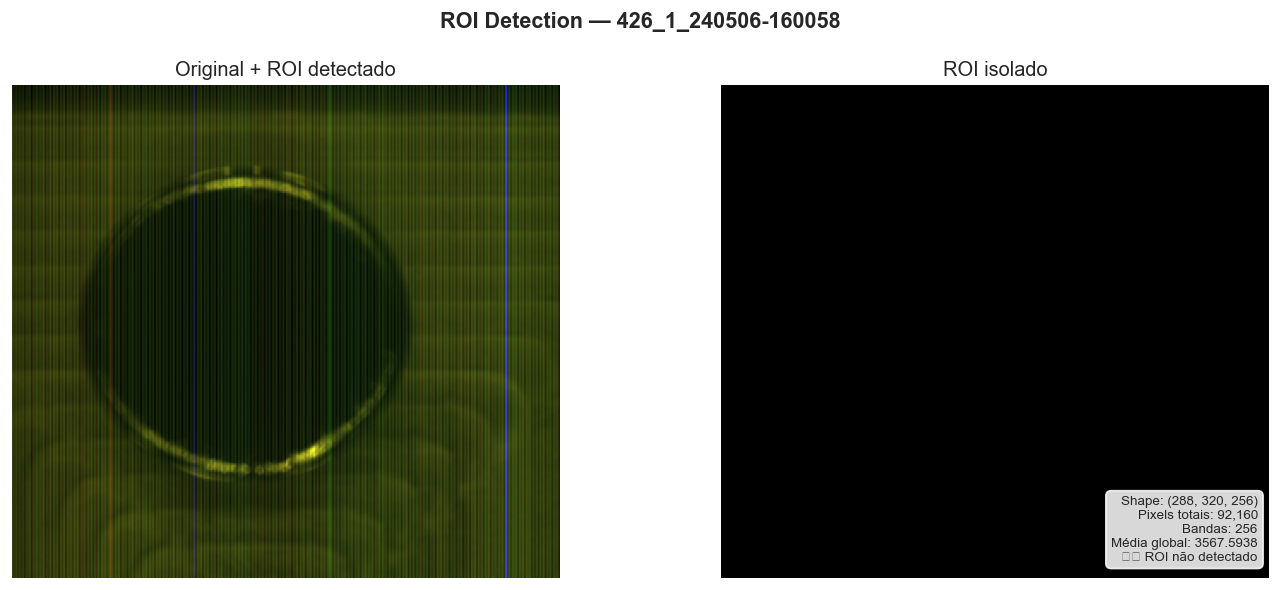

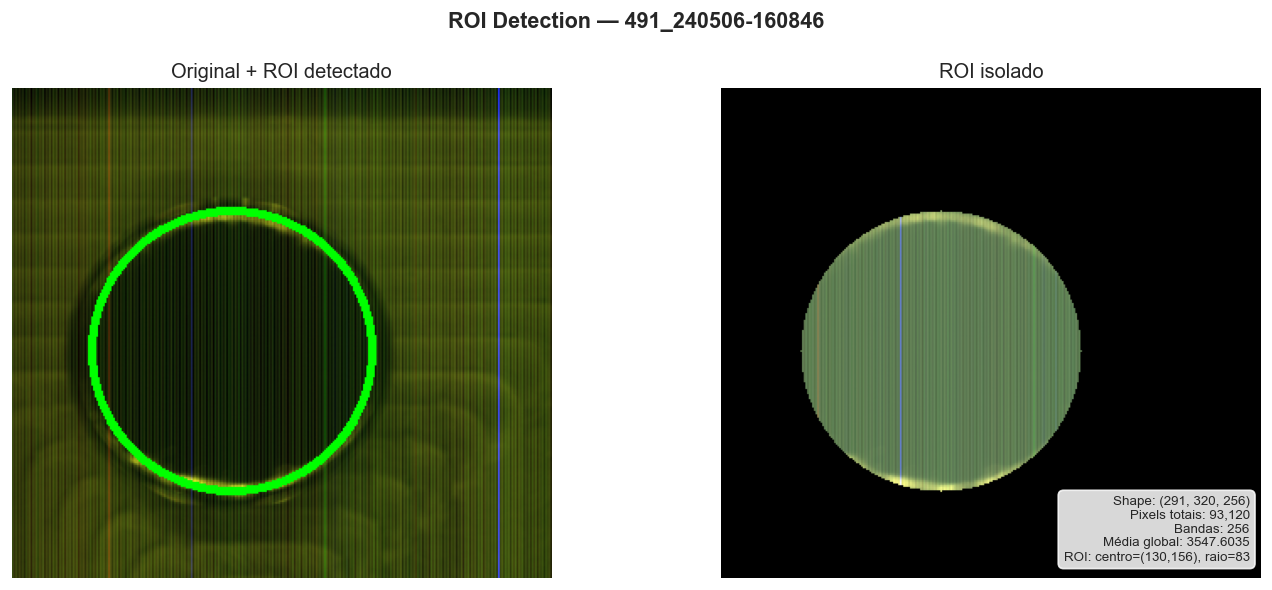

In [7]:
def visualizar_roi(folder_name: str, salvar=True):
    """
    Carrega a imagem HSI, detecta o ROI circular e plota:
    - Imagem RGB original com círculo detectado
    - Imagem RGB apenas do ROI
    - Informações da imagem
    """
    hdr_path = os.path.join(HSI_ROOT, folder_name, 'capture', f'{folder_name}.hdr')
    if not os.path.exists(hdr_path):
        print(f'❌ Arquivo não encontrado: {hdr_path}')
        return

    img = spectral.open_image(hdr_path).load()
    altura, largura, n_bandas = img.shape

    rgb       = spectral.get_rgb(img, [50, 30, 10])
    rgb_uint8 = (rgb * 255).astype(np.uint8)
    gray      = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2GRAY)
    gray_blur = cv2.GaussianBlur(gray, (7, 7), 2)

    circles = cv2.HoughCircles(
        gray_blur, cv2.HOUGH_GRADIENT,
        dp=1.2, minDist=100, param1=100, param2=30,
        minRadius=50, maxRadius=200
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'ROI Detection — {folder_name}', fontsize=13, fontweight='bold')

    # --- Imagem original com círculo marcado ---
    rgb_marcado = rgb_uint8.copy()
    mask = np.zeros(gray.shape, dtype=np.uint8)

    if circles is not None:
        x, y, r = [int(v) for v in circles[0][0]]
        cv2.circle(rgb_marcado, (x, y), r, (0, 255, 0), 3)
        cv2.circle(mask, (x, y), r, 1, thickness=-1)
        status = f'ROI: centro=({x},{y}), raio={r}'
    else:
        status = '⚠️ ROI não detectado'

    axes[0].imshow(rgb_marcado)
    axes[0].set_title('Original + ROI detectado')
    axes[0].axis('off')

    # --- ROI isolado ---
    mask3d  = np.repeat(mask[:, :, np.newaxis], img.shape[2], axis=2)
    roi     = img * mask3d
    roi_rgb = spectral.get_rgb(roi, [50, 30, 10])
    roi_rgb = roi_rgb / (roi_rgb.max() + 1e-8)

    axes[1].imshow(roi_rgb)
    axes[1].set_title('ROI isolado')
    axes[1].axis('off')

    # Info box
    espectros = img.reshape(altura * largura, n_bandas)
    info = (
        f'Shape: {img.shape}\n'
        f'Pixels totais: {altura * largura:,}\n'
        f'Bandas: {n_bandas}\n'
        f'Média global: {espectros.mean():.4f}\n'
        f'{status}'
    )
    axes[1].text(
        0.98, 0.03, info,
        transform=axes[1].transAxes, fontsize=8,
        va='bottom', ha='right',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85)
    )

    plt.tight_layout()
    if salvar:
        plt.savefig(os.path.join(FIGS_DIR, f'roi_{folder_name}.png'), bbox_inches='tight')
    plt.show()


# Plota o ROI das primeiras 4 imagens disponíveis
for pasta in pastas[:4]:
    visualizar_roi(pasta)

## 2. Média Espectral por Banda — comparação entre imagens

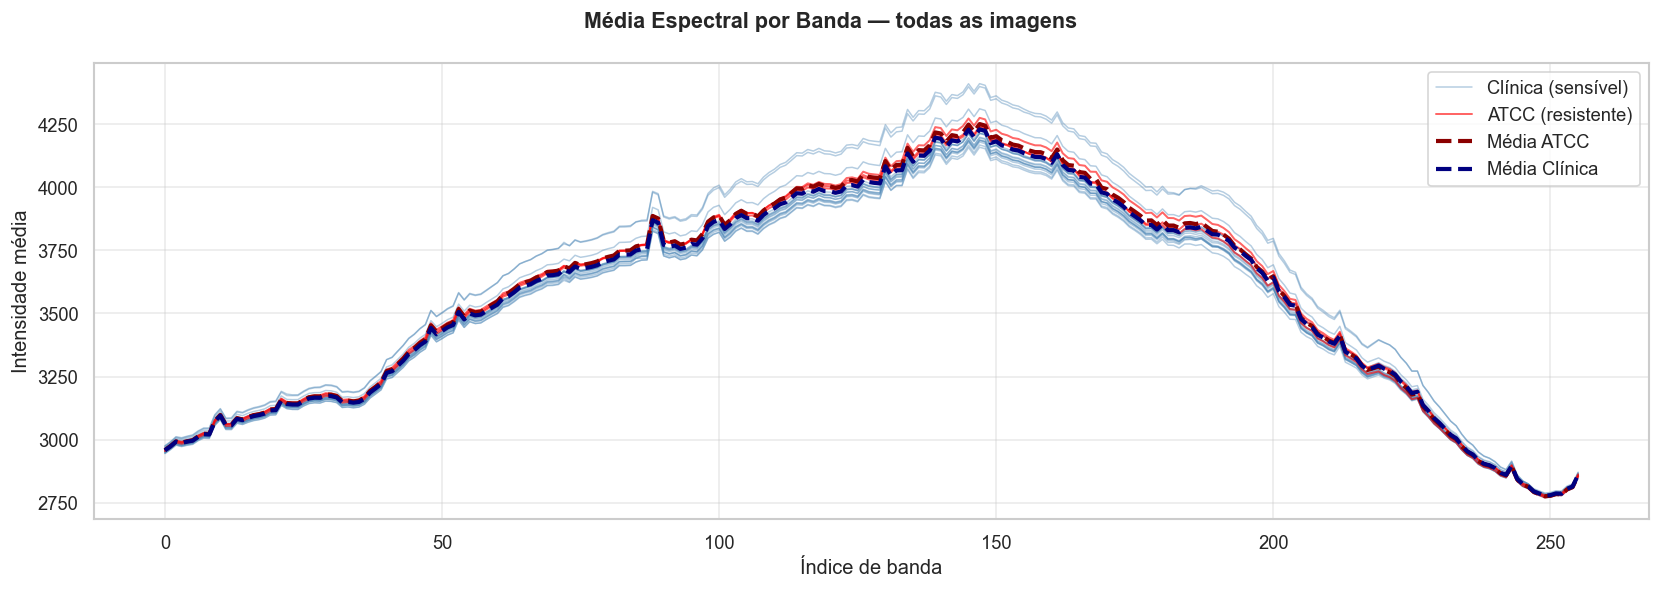

In [8]:
def carregar_media_espectral(folder_name: str):
    """Carrega a imagem HSI e retorna a média espectral por banda."""
    hdr_path = os.path.join(HSI_ROOT, folder_name, 'capture', f'{folder_name}.hdr')
    if not os.path.exists(hdr_path):
        return None
    img = spectral.open_image(hdr_path).load()
    h, w, b = img.shape
    return img.reshape(h * w, b).mean(axis=0)


# Identifica ATCCs vs clínicas
ATCC_PREFIXOS = ['ATCC13', 'ATCC16', 'ATCC27']
is_atcc = lambda nome: any(p in nome for p in ATCC_PREFIXOS)

fig, ax = plt.subplots(figsize=(14, 5))
fig.suptitle('Média Espectral por Banda — todas as imagens', fontsize=13, fontweight='bold')

medias_atcc    = []
medias_clinica = []

for pasta in pastas:
    media = carregar_media_espectral(pasta)
    if media is None:
        continue
    bandas = np.arange(len(media))
    if is_atcc(pasta):
        ax.plot(bandas, media, color='red', alpha=0.6, linewidth=1.2, label='ATCC (resistente)')
        medias_atcc.append(media)
    else:
        ax.plot(bandas, media, color='steelblue', alpha=0.4, linewidth=0.9, label='Clínica (sensível)')
        medias_clinica.append(media)

# Média global por grupo
if medias_atcc:
    ax.plot(np.mean(medias_atcc, axis=0), color='darkred', linewidth=2.5,
            linestyle='--', label='Média ATCC')
if medias_clinica:
    ax.plot(np.mean(medias_clinica, axis=0), color='navy', linewidth=2.5,
            linestyle='--', label='Média Clínica')

# Remove labels duplicadas na legenda
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys())

ax.set_xlabel('Índice de banda')
ax.set_ylabel('Intensidade média')
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'media_espectral_todos.png'), bbox_inches='tight')
plt.show()

## 3. Comparação direta entre duas imagens (ATCC vs Clínica)

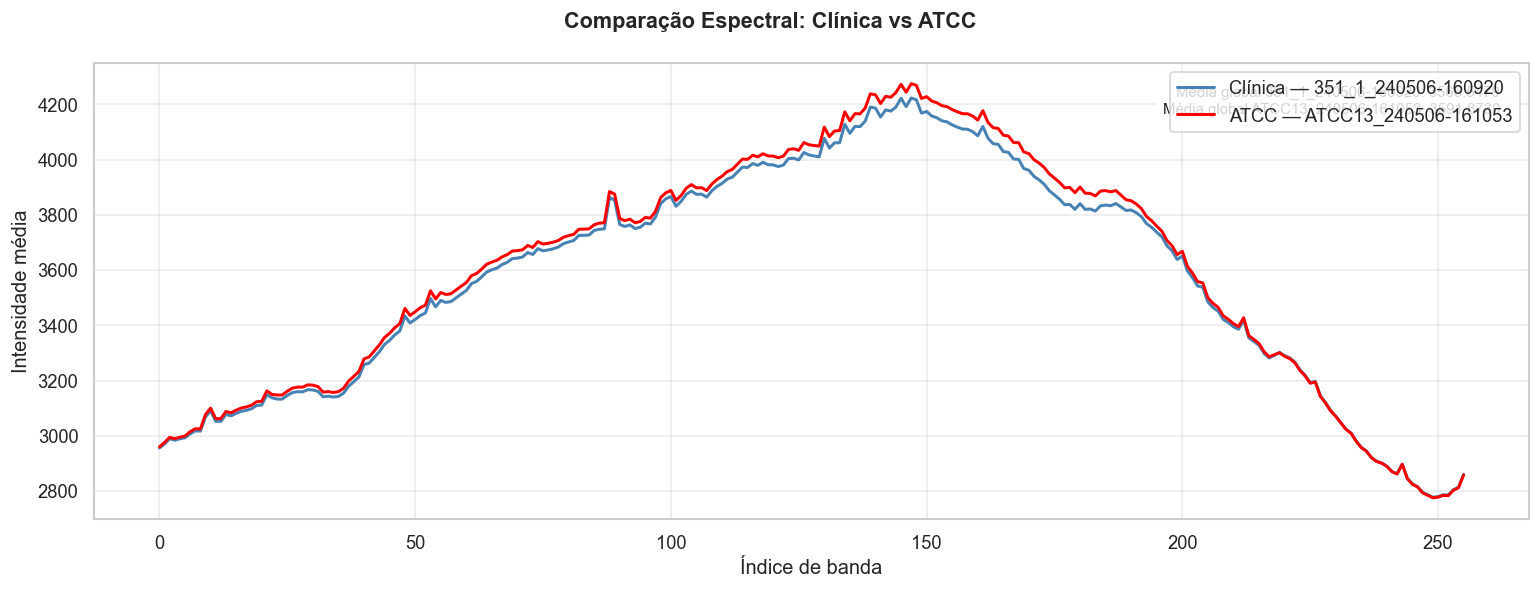

In [9]:
# Escolha as imagens que quer comparar
IMAGEM_A = pastas[0]   # primeira clínica disponível
IMAGEM_B = next((p for p in pastas if is_atcc(p)), None)  # primeira ATCC disponível

if IMAGEM_B is None:
    print('⚠️  Nenhuma imagem ATCC encontrada nas pastas.')
else:
    media_a = carregar_media_espectral(IMAGEM_A)
    media_b = carregar_media_espectral(IMAGEM_B)

    fig, ax = plt.subplots(figsize=(13, 5))
    fig.suptitle('Comparação Espectral: Clínica vs ATCC', fontsize=13, fontweight='bold')

    bandas = np.arange(len(media_a))
    ax.plot(bandas, media_a, color='steelblue', linewidth=1.8, label=f'Clínica — {IMAGEM_A}')
    ax.plot(bandas, media_b, color='red',       linewidth=1.8, label=f'ATCC — {IMAGEM_B}')

    ax.set_xlabel('Índice de banda')
    ax.set_ylabel('Intensidade média')
    ax.legend()
    ax.grid(True, alpha=0.4)

    info = (
        f'Média global {IMAGEM_A}: {media_a.mean():.4f}\n'
        f'Média global {IMAGEM_B}: {media_b.mean():.4f}'
    )
    ax.text(0.98, 0.95, info, transform=ax.transAxes,
            fontsize=9, va='top', ha='right',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85))

    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, 'comparacao_clinica_atcc.png'), bbox_inches='tight')
    plt.show()

## 4. ROI — Espectros dos pixels + SNR por banda

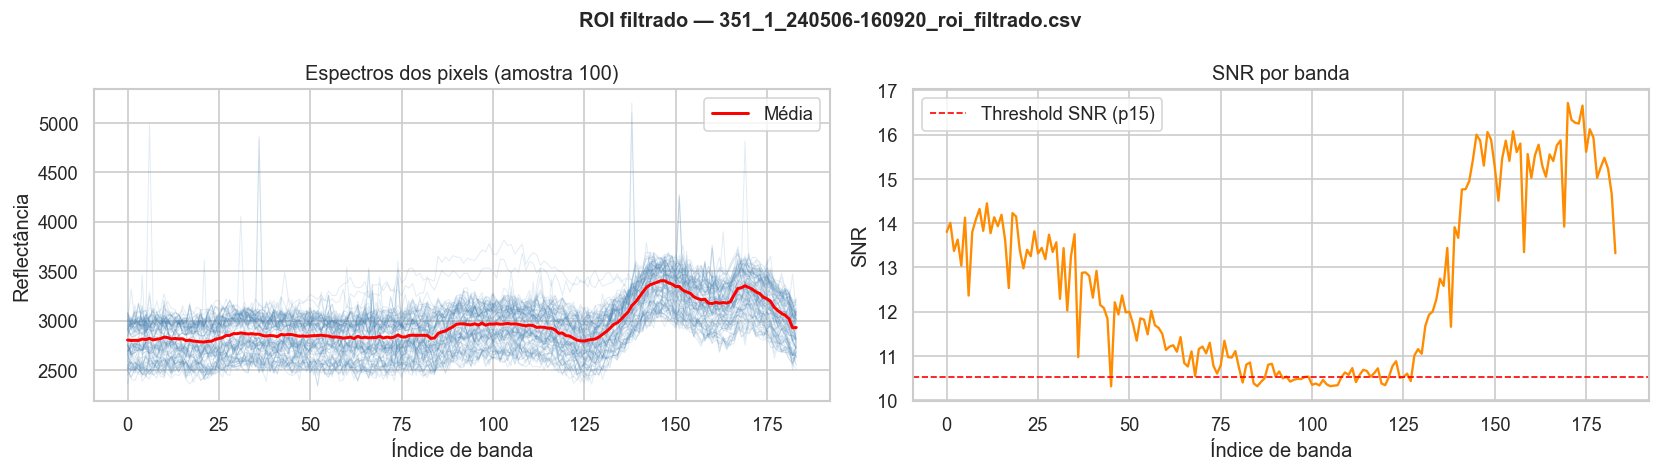

✅ Shape ROI: (19107, 184)


In [10]:
roi_files = [f for f in os.listdir(HSI_ROOT) if f.endswith('_roi_filtrado.csv')]

if not roi_files:
    print('⚠️ Nenhum ROI filtrado encontrado. Execute main.py primeiro.')
else:
    roi_path  = os.path.join(HSI_ROOT, roi_files[0])
    df_roi    = pd.read_csv(roi_path)
    espectros = df_roi.values
    bandas    = np.arange(espectros.shape[1])

    idx_sample = np.random.choice(len(espectros), size=min(100, len(espectros)), replace=False)
    mean_b     = np.mean(espectros, axis=0)
    std_b      = np.std(espectros,  axis=0)
    snr_b      = np.where(std_b > 0, mean_b / std_b, 0)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'ROI filtrado — {roi_files[0]}', fontsize=12, fontweight='bold')

    for i in idx_sample:
        axes[0].plot(bandas, espectros[i], alpha=0.15, color='steelblue', linewidth=0.6)
    axes[0].plot(bandas, mean_b, color='red', linewidth=1.8, label='Média')
    axes[0].set_title('Espectros dos pixels (amostra 100)')
    axes[0].set_xlabel('Índice de banda')
    axes[0].set_ylabel('Reflectância')
    axes[0].legend()

    axes[1].plot(bandas, snr_b, color='darkorange', linewidth=1.4)
    axes[1].axhline(np.percentile(snr_b, 15), color='red', linestyle='--',
                    linewidth=1, label='Threshold SNR (p15)')
    axes[1].set_title('SNR por banda')
    axes[1].set_xlabel('Índice de banda')
    axes[1].set_ylabel('SNR')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, 'roi_espectros_snr.png'), bbox_inches='tight')
    plt.show()
    print(f'✅ Shape ROI: {espectros.shape}')

## 5. Comparação das 3 transformações espectrais

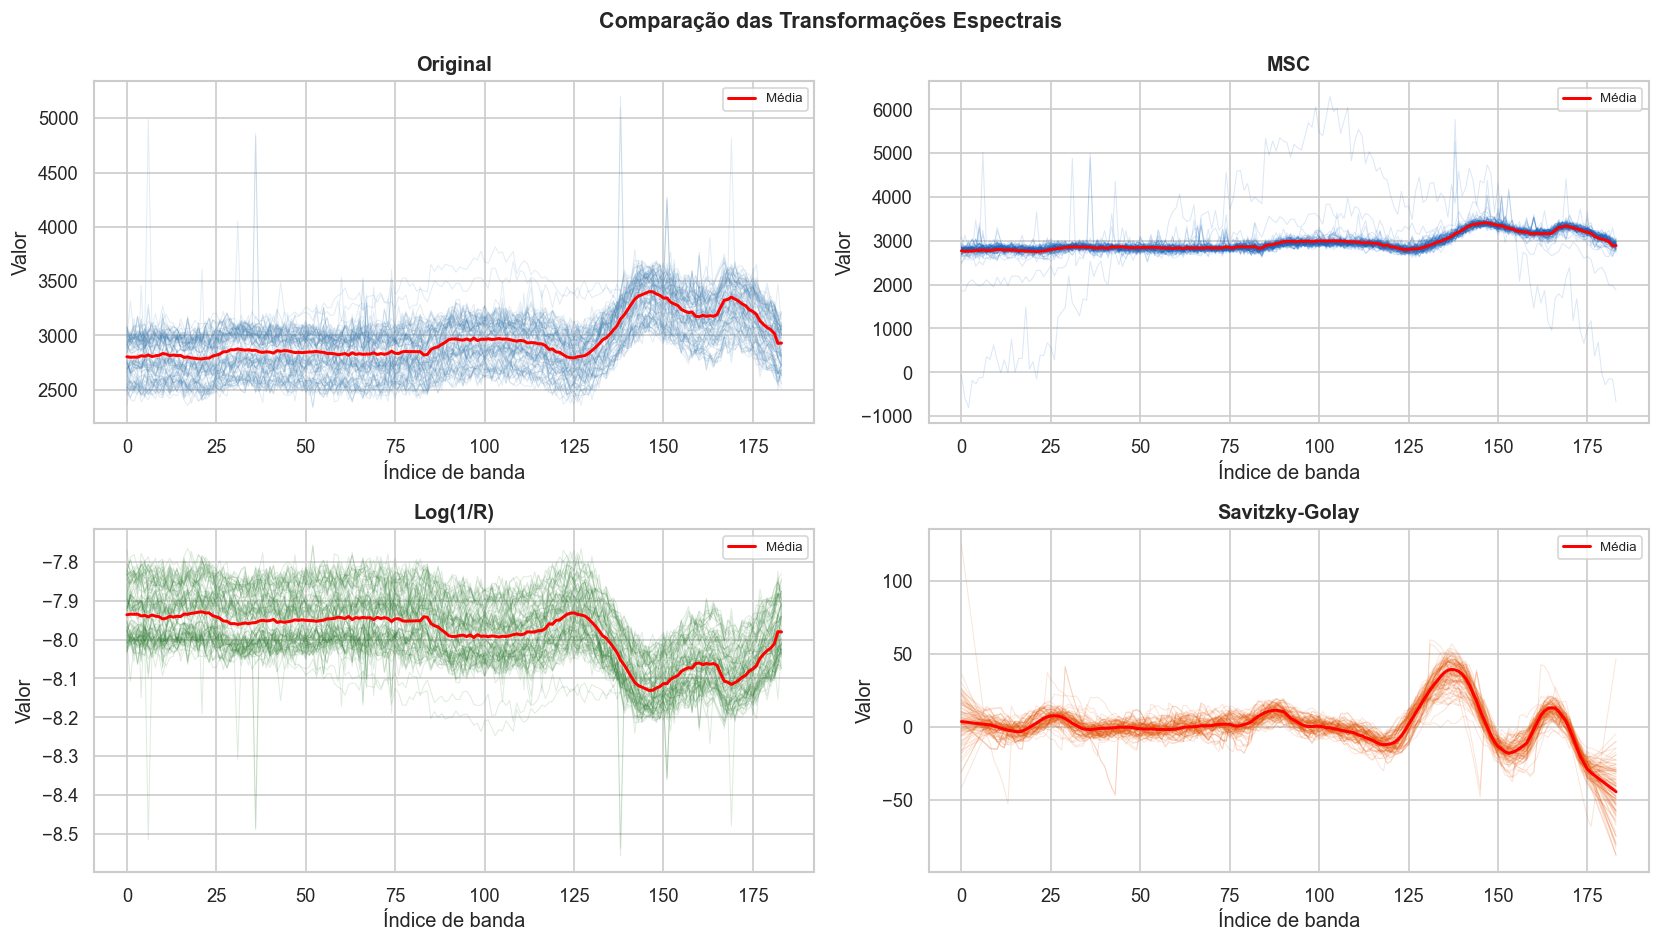

In [13]:
def msc_signal(data):
    ref = np.mean(data, axis=0)
    corrected = []
    for s in data:
        c = np.polyfit(ref, s, 1)
        corrected.append(s if abs(c[0]) < 1e-10 else (s - c[1]) / c[0])
    return np.array(corrected)

def log_transform(data):
    d = data.copy()
    d[d <= 0] = 1e-6
    return -np.log(d)

def derivative_transform(data):
    return savgol_filter(data, window_length=15, polyorder=2, deriv=1, axis=1)

if roi_files:
    transformacoes = {
        'Original':       espectros,
        'MSC':            msc_signal(espectros),
        'Log(1/R)':       log_transform(espectros),
        'Savitzky-Golay': derivative_transform(espectros),
    }
    cores = ['steelblue', '#1565C0', '#2E7D32', '#E65100']

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    fig.suptitle('Comparação das Transformações Espectrais', fontsize=13, fontweight='bold')

    for ax, (nome, dados), cor in zip(axes.flatten(), transformacoes.items(), cores):
        for i in idx_sample:
            ax.plot(bandas, dados[i], alpha=0.15, color=cor, linewidth=0.6)
        ax.plot(bandas, np.mean(dados, axis=0), color='red', linewidth=1.8, label='Média')
        ax.set_title(nome, fontweight='bold')
        ax.set_xlabel('Índice de banda')
        ax.set_ylabel('Valor')
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, 'comparacao_transformacoes.png'), bbox_inches='tight')
    plt.show()

## 6. Distribuição de classes por pipeline

✅ msc_mi: (223762, 35)
✅ msc_xgb: (223762, 35)
✅ log_mi: (223762, 35)
✅ log_xgb: (223762, 35)
✅ deriv_mi: (223762, 35)
✅ deriv_xgb: (223762, 35)


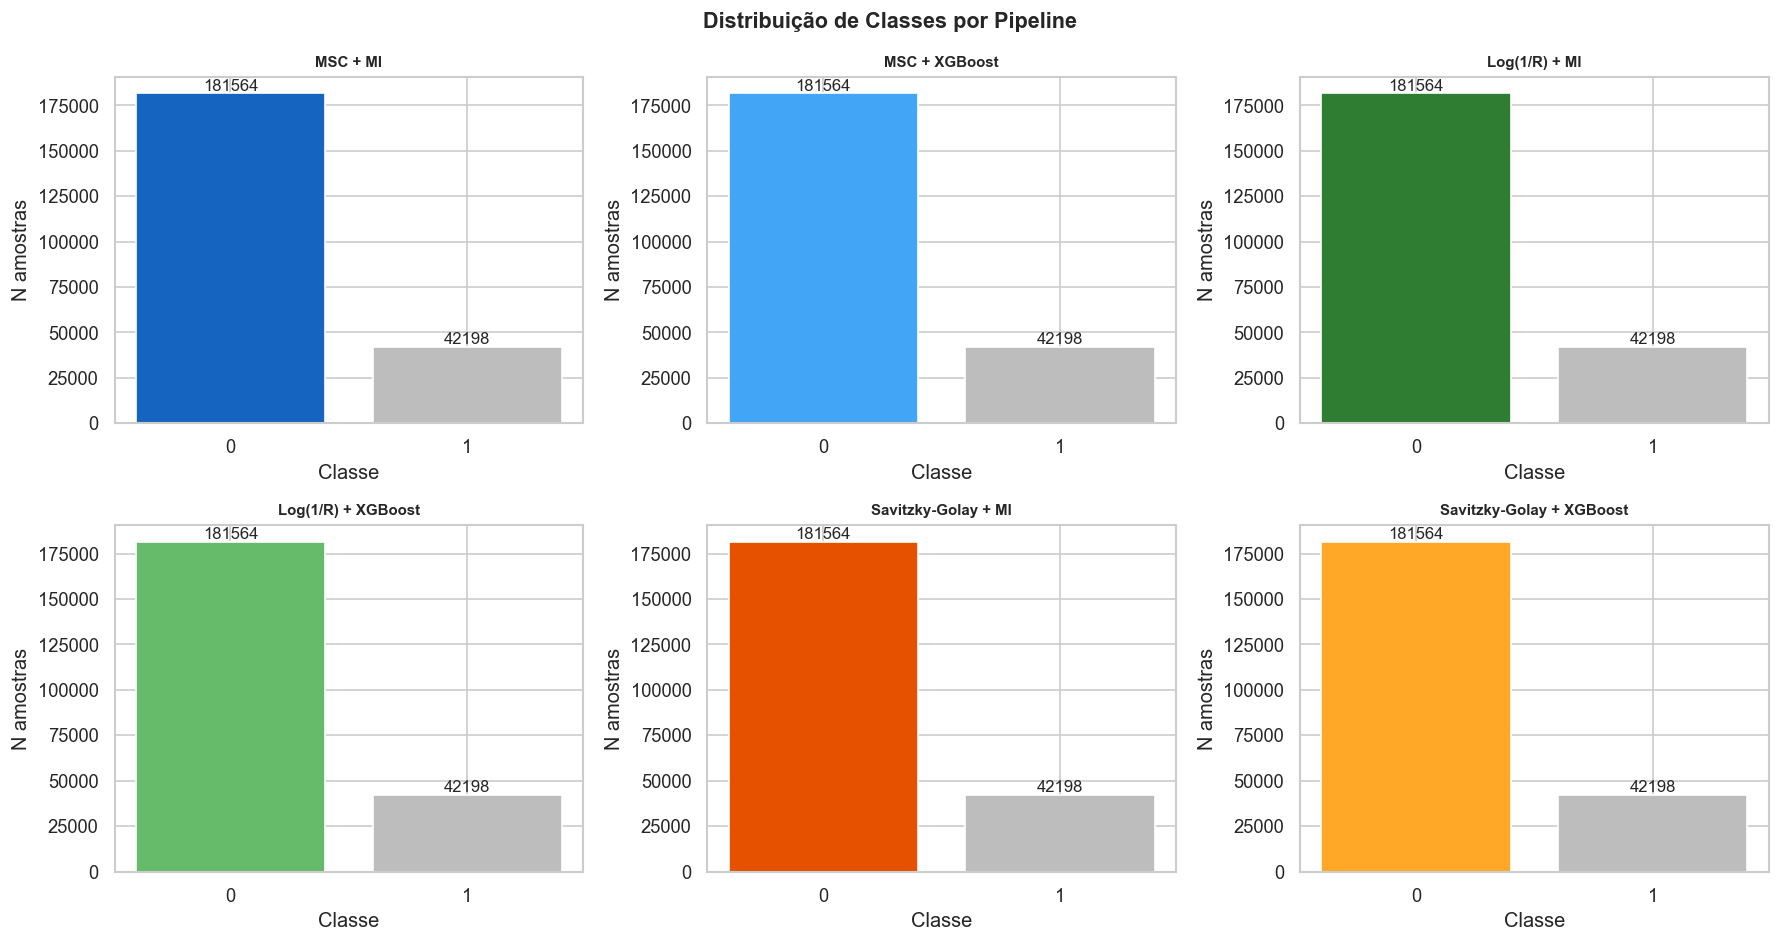

In [14]:
datasets = {}
for branch in BRANCHES:
    path = os.path.join(FEATURES_DIR, f'dataset_{branch}.csv')
    if os.path.exists(path):
        datasets[branch] = pd.read_csv(path)
        print(f'✅ {branch}: {datasets[branch].shape}')
    else:
        print(f'⚠️  dataset_{branch}.csv não encontrado')

if datasets:
    n   = len(datasets)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle('Distribuição de Classes por Pipeline', fontsize=13, fontweight='bold')

    for ax, (branch, df) in zip(axes.flatten(), datasets.items()):
        counts = df['label'].value_counts().sort_index()
        bars   = ax.bar(counts.index.astype(str), counts.values,
                        color=[BRANCH_COLORS[branch], '#BDBDBD'])
        ax.set_title(BRANCH_LABELS[branch], fontweight='bold', fontsize=9)
        ax.set_xlabel('Classe')
        ax.set_ylabel('N amostras')
        for bar, v in zip(bars, counts.values):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.05, str(v),
                    ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, 'distribuicao_classes.png'), bbox_inches='tight')
    plt.show()

## 7. Comparação final — métricas dos 6 pipelines

In [15]:
relatorio_path = os.path.join(RESULTS_DIR, 'comparacao_pipelines.csv')

if not os.path.exists(relatorio_path):
    print('⚠️  comparacao_pipelines.csv não encontrado. Execute train.py primeiro.')
else:
    df_comp  = pd.read_csv(relatorio_path)
    metricas = [m for m in ['acuracia', 'f1', 'precisao', 'recall', 'roc_auc'] if m in df_comp.columns]

    # Barras agrupadas
    x = np.arange(len(metricas))
    w = 0.13

    fig, ax = plt.subplots(figsize=(14, 5))
    for i, row in df_comp.iterrows():
        branch = row['pipeline']
        vals   = [row[m] for m in metricas]
        bars   = ax.bar(x + i * w, vals, width=w,
                        label=BRANCH_LABELS.get(branch, branch),
                        color=BRANCH_COLORS.get(branch, f'C{i}'))
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.005,
                    f'{v:.2f}', ha='center', va='bottom', fontsize=6.5)

    ax.set_xticks(x + w * 2.5)
    ax.set_xticklabels([m.capitalize() for m in metricas])
    ax.set_ylim(0, 1.15)
    ax.set_ylabel('Score')
    ax.set_title('Comparação de Métricas — 6 pipelines', fontsize=12, fontweight='bold')
    ax.legend(fontsize=8, ncol=3)
    ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8)

    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, 'comparacao_metricas.png'), bbox_inches='tight')
    plt.show()

    # Radar
    angles = np.linspace(0, 2 * np.pi, len(metricas), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    fig.suptitle('Radar — 6 pipelines', fontsize=12, fontweight='bold')

    for _, row in df_comp.iterrows():
        branch = row['pipeline']
        vals   = [row[m] for m in metricas] + [row[metricas[0]]]
        ax.plot(angles, vals, linewidth=2,
                label=BRANCH_LABELS.get(branch, branch),
                color=BRANCH_COLORS.get(branch, 'gray'))
        ax.fill(angles, vals, alpha=0.07,
                color=BRANCH_COLORS.get(branch, 'gray'))

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([m.capitalize() for m in metricas], fontsize=10)
    ax.set_ylim(0, 1)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGS_DIR, 'radar_metricas.png'), bbox_inches='tight')
    plt.show()

    print('\n📊 Tabela comparativa:')
    print(df_comp[['pipeline'] + metricas].to_string(index=False))
    melhor = df_comp.loc[df_comp['acuracia'].idxmax()]
    print(f'\n🏆 Melhor pipeline: {melhor["pipeline"]} — Acurácia: {melhor["acuracia"]:.4f}')

⚠️  comparacao_pipelines.csv não encontrado. Execute train.py primeiro.


## 8. Resumo dos arquivos gerados

In [ ]:
figs = sorted(os.listdir(FIGS_DIR))
print(f'📁 {len(figs)} figuras salvas em: {FIGS_DIR}')
for f in figs:
    print(f'   {f}')